# BÀI THỰC HÀNH 7: ĐÁNH GIÁ MÔ HÌNH



In [1]:
# Thiết lập thư viện và nạp dữ liệu
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.datasets import load_digits

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

path_data = "data/sinh_vien_bo_hoc.csv" if os.path.exists("data/sinh_vien_bo_hoc.csv") else "sinh_vien_bo_hoc.csv"
df = pd.read_csv(path_data)
print(f"Kích thước tập dữ liệu: {df.shape}")
print(f"Tỷ lệ sinh viên bỏ học: {df['bo_hoc'].mean():.3%}")


Kích thước tập dữ liệu: (1200, 5)
Tỷ lệ sinh viên bỏ học: 9.917%


---
## 1. Khi Accuracy đánh lừa trên dữ liệu lệch lớp (h1_do_bua.py)
Với dữ liệu chỉ có ~10% mẫu dương (bỏ học), mô hình lười đoán mọi sinh viên đều không bỏ học vẫn đạt accuracy 90% nhưng tìm được 0 người có nguy cơ.


Tập kiểm tra: 300 bạn, trong đó có 30 bạn bỏ học thật

Mô hình lười       Accuracy: 0.9000 | Tìm ra:  0/30 bạn bỏ học
Hồi quy Logistic   Accuracy: 0.9467 | Tìm ra: 17/30 bạn bỏ học


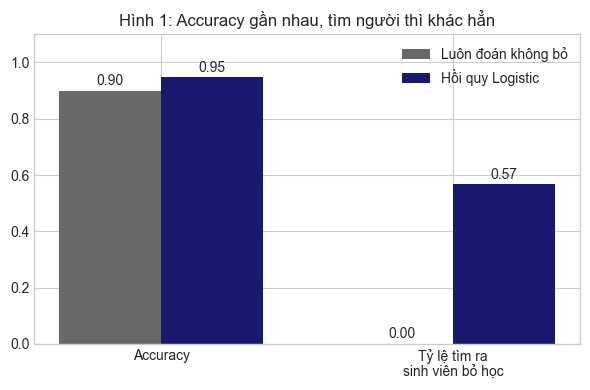

In [2]:
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print(f"Tập kiểm tra: {len(y_te)} bạn, trong đó có {y_te.sum()} bạn bỏ học thật\n")

# Mô hình lười vs Hồi quy Logistic
luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_luoi = luoi.predict(X_te)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
du_lr = lr.predict(X_te)

for ten, du in [("Mô hình lười", du_luoi), ("Hồi quy Logistic", du_lr)]:
    acc = accuracy_score(y_te, du)
    tim_ra = ((du == 1) & (y_te == 1)).sum()
    print(f"{ten:18s} Accuracy: {acc:.4f} | Tìm ra: {tim_ra:2d}/{y_te.sum()} bạn bỏ học")

# Vẽ biểu đồ so sánh Accuracy vs Tỷ lệ phát hiện (Hình 1)
fig, ax = plt.subplots(figsize=(6, 4))
labels = ['Accuracy', 'Tỷ lệ tìm ra\nsinh viên bỏ học']
luoi_vals = [accuracy_score(y_te, du_luoi), ((du_luoi == 1) & (y_te == 1)).sum() / y_te.sum()]
lr_vals = [accuracy_score(y_te, du_lr), ((du_lr == 1) & (y_te == 1)).sum() / y_te.sum()]

x_pos = np.arange(len(labels))
width = 0.35
ax.bar(x_pos - width/2, luoi_vals, width, label='Luôn đoán không bỏ', color='dimgray')
ax.bar(x_pos + width/2, lr_vals, width, label='Hồi quy Logistic', color='midnightblue')
for i in range(len(labels)):
    ax.text(x_pos[i] - width/2, luoi_vals[i] + 0.02, f"{luoi_vals[i]:.2f}", ha='center')
    ax.text(x_pos[i] + width/2, lr_vals[i] + 0.02, f"{lr_vals[i]:.2f}", ha='center')
ax.set_xticks(x_pos)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.1)
ax.set_title("Hình 1: Accuracy gần nhau, tìm người thì khác hẳn")
ax.legend()
plt.tight_layout()
plt.show()


---
## 2. Ma trận nhầm lẫn (h2_ma_tran.py)
Bốn ô cơ bản: $TN$ (đoán đúng 0), $FP$ (báo động nhầm), $FN$ (bỏ sót), $TP$ (đoán đúng 1).  
Thứ tự khi trải mảng của Scikit-Learn: `tn, fp, fn, tp = m.ravel()`.


Tự đếm bằng NumPy:
  TP = 17 (đoán bỏ, thật sự bỏ)
  FP = 3 (báo động nhầm)
  FN = 13 (bỏ sót)
  TN = 267 (đoán không, đúng là không)
  Tổng = 300

confusion_matrix của scikit-learn:
[[267   3]
 [ 13  17]]
Thứ tự trải phẳng (TN, FP, FN, TP): [267   3  13  17]


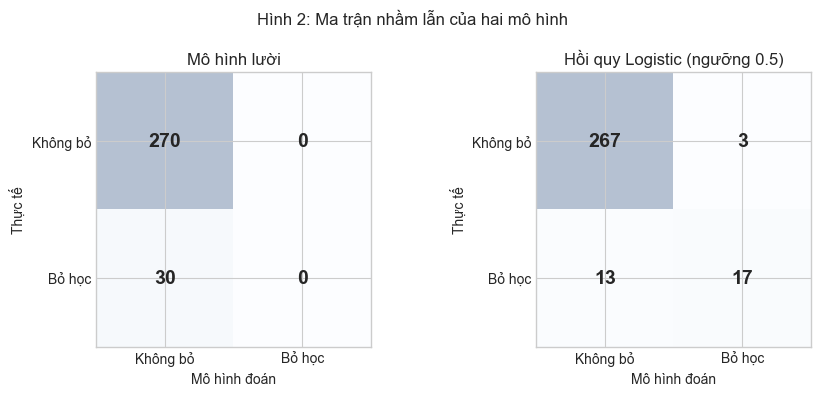

In [3]:
that = y_te.to_numpy()
du = du_lr

tp = np.sum((that == 1) & (du == 1))
fp = np.sum((that == 0) & (du == 1))
fn = np.sum((that == 1) & (du == 0))
tn = np.sum((that == 0) & (du == 0))

print("Tự đếm bằng NumPy:")
print(f"  TP = {tp} (đoán bỏ, thật sự bỏ)")
print(f"  FP = {fp} (báo động nhầm)")
print(f"  FN = {fn} (bỏ sót)")
print(f"  TN = {tn} (đoán không, đúng là không)")
print(f"  Tổng = {tp + fp + fn + tn}\n")

m = confusion_matrix(that, du)
print("confusion_matrix của scikit-learn:")
print(m)
print("Thứ tự trải phẳng (TN, FP, FN, TP):", m.ravel())

# Vẽ ma trận nhầm lẫn (Hình 2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
m_luoi = confusion_matrix(that, du_luoi)
for ax, cm, title in [(ax1, m_luoi, "Mô hình lười"), (ax2, m, "Hồi quy Logistic (ngưỡng 0.5)")]:
    im = ax.imshow(cm, cmap="Blues", alpha=0.3)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Không bỏ", "Bỏ học"])
    ax.set_yticklabels(["Không bỏ", "Bỏ học"])
    ax.set_xlabel("Mô hình đoán")
    ax.set_ylabel("Thực tế")
    ax.set_title(title)
    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r, c]), ha="center", va="center", fontsize=14, fontweight="bold")
plt.suptitle("Hình 2: Ma trận nhầm lẫn của hai mô hình")
plt.tight_layout()
plt.show()


---
## 3. Precision, Recall và F1-score (h3_precision_recall.py)
- **Precision:** $\frac{TP}{TP+FP}$ (Báo động thì đúng bao nhiêu %).
- **Recall:** $\frac{TP}{TP+FN}$ (Bắt trúng bao nhiêu % tổng số người bỏ học).
- **F1:** Trung bình điều hoà của Precision và Recall.


In [4]:
p = tp / (tp + fp)
r = tp / (tp + fn)
f1 = 2 * p * r / (p + r)

print("Tính tay:")
print(f"  Precision = {tp}/({tp}+{fp}) = {p:.4f}")
print(f"  Recall    = {tp}/({tp}+{fn}) = {r:.4f}")
print(f"  F1-score  = {f1:.4f}\n")

print("Dùng scikit-learn:")
print(f"  Precision = {precision_score(y_te, du):.4f}")
print(f"  Recall    = {recall_score(y_te, du):.4f}")
print(f"  F1-score  = {f1_score(y_te, du):.4f}\n")

print("Báo cáo phân loại đầy đủ:")
print(classification_report(y_te, du, digits=4, target_names=["khong bo", "bo hoc"]))


Tính tay:
  Precision = 17/(17+3) = 0.8500
  Recall    = 17/(17+13) = 0.5667
  F1-score  = 0.6800

Dùng scikit-learn:
  Precision = 0.8500
  Recall    = 0.5667
  F1-score  = 0.6800

Báo cáo phân loại đầy đủ:
              precision    recall  f1-score   support

    khong bo     0.9536    0.9889    0.9709       270
      bo hoc     0.8500    0.5667    0.6800        30

    accuracy                         0.9467       300
   macro avg     0.9018    0.7778    0.8255       300
weighted avg     0.9432    0.9467    0.9418       300



---
## 4. Đổi ngưỡng quyết định và chọn ngưỡng tối ưu (h4_nguong.py)
Hạ ngưỡng giúp tăng Recall (ít bỏ sót hơn) nhưng chấp nhận tăng báo động nhầm (giảm Precision).  
**Quy tắc:** Chỉ chọn ngưỡng tối ưu trên tập học bằng kiểm định chéo (`cross_val_predict`), không nhìn tập test!


Khảo sát các ngưỡng trên tập kiểm tra:
Ngưỡng  Số báo   TP   FP   FN   Precision   Recall      F1
  0.5       20    17    3   13    0.8500     0.5667  0.6800
  0.4       21    18    3   12    0.8571     0.6000  0.7059
  0.3       29    21    8    9    0.7241     0.7000  0.7119
  0.2       42    24   18    6    0.5714     0.8000  0.6667
  0.1       61    26   35    4    0.4262     0.8667  0.5714

Ngưỡng cho F1 cao nhất trên tập học: 0.25 (F1 CV: 0.6473)
Tập kiểm tra với ngưỡng 0.25:
  Precision: 0.6571 | Recall: 0.7667 | F1: 0.7077


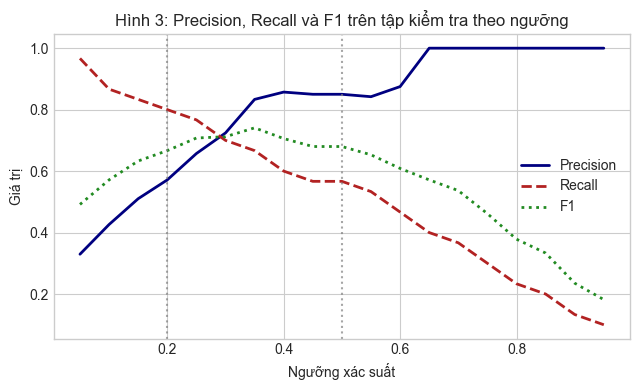

In [5]:
xs_te = lr.predict_proba(X_te)[:, 1]

print("Khảo sát các ngưỡng trên tập kiểm tra:")
print("Ngưỡng  Số báo   TP   FP   FN   Precision   Recall      F1")
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    du_t = (xs_te >= t).astype(int)
    tp_t = int(((du_t == 1) & (y_te == 1)).sum())
    fp_t = int(((du_t == 1) & (y_te == 0)).sum())
    fn_t = int(((du_t == 0) & (y_te == 1)).sum())
    print(f"  {t:.1f}     {du_t.sum():4d}   {tp_t:3d}  {fp_t:3d}  {fn_t:3d}    {precision_score(y_te, du_t):.4f}     {recall_score(y_te, du_t):.4f}  {f1_score(y_te, du_t):.4f}")
print()

# Chọn ngưỡng tối ưu F1 trên tập học bằng 5-fold CV
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1_hoc = [f1_score(y_tr, (xs_hoc >= t).astype(int)) for t in cac_nguong]
t_tot = cac_nguong[int(np.argmax(f1_hoc))]
print(f"Ngưỡng cho F1 cao nhất trên tập học: {t_tot} (F1 CV: {max(f1_hoc):.4f})")

# Áp dụng ngưỡng tối ưu vào tập kiểm tra
du_opt = (xs_te >= t_tot).astype(int)
print(f"Tập kiểm tra với ngưỡng {t_tot}:")
print(f"  Precision: {precision_score(y_te, du_opt):.4f} | Recall: {recall_score(y_te, du_opt):.4f} | F1: {f1_score(y_te, du_opt):.4f}")

# Vẽ đường cong Precision - Recall - F1 theo ngưỡng (Hình 3)
p_curve = [precision_score(y_te, (xs_te >= t).astype(int), zero_division=0) for t in cac_nguong]
r_curve = [recall_score(y_te, (xs_te >= t).astype(int)) for t in cac_nguong]
f1_curve = [f1_score(y_te, (xs_te >= t).astype(int)) for t in cac_nguong]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(cac_nguong, p_curve, 'navy', lw=2, label='Precision')
ax.plot(cac_nguong, r_curve, 'firebrick', lw=2, linestyle='--', label='Recall')
ax.plot(cac_nguong, f1_curve, 'forestgreen', lw=2, linestyle=':', label='F1')
ax.axvline(0.2, color='gray', linestyle=':', alpha=0.7)
ax.axvline(0.5, color='gray', linestyle=':', alpha=0.7)
ax.set_xlabel("Ngưỡng xác suất")
ax.set_ylabel("Giá trị")
ax.set_title("Hình 3: Precision, Recall và F1 trên tập kiểm tra theo ngưỡng")
ax.legend()
plt.tight_layout()
plt.show()


---
## 5. Đường cong ROC và chỉ số AUC (h5_roc_auc.py)
ROC biểu diễn đánh đổi giữa **Tỷ lệ báo động nhầm (FPR)** và **Recall (TPR)** tại mọi ngưỡng khả dĩ.  
Chỉ số AUC đo diện tích dưới đường ROC: AUC = 1.0 (hoàn hảo), AUC = 0.5 (đoán mò).


AUC của Logistic Regression: 0.9449

So sánh các mô hình trên tập kiểm tra:
Mô hình          AUC      Recall   F1 (ngưỡng 0.5)
 Logistic        0.9449   0.5667   0.6800
 Naive Bayes     0.9336   0.3667   0.5116
 KNN, k = 15     0.9274   0.2333   0.3684
 Cây sâu 4       0.8803   0.4667   0.5957
 Rừng 200 cây    0.9249   0.5667   0.6538
 SVM RBF         0.8996   0.5000   0.6250


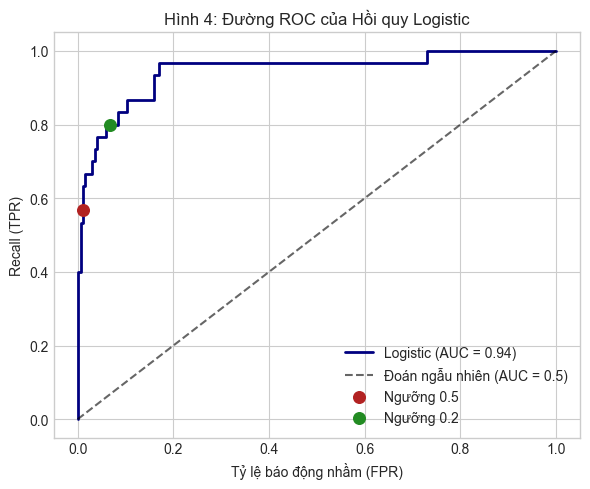

In [6]:
fpr, tpr, _ = roc_curve(y_te, xs_te)
print(f"AUC của Logistic Regression: {roc_auc_score(y_te, xs_te):.4f}\n")

mo_hinh = {
    "Logistic"     : lr,
    "Naive Bayes"  : GaussianNB(),
    "KNN, k = 15"  : make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
    "Cây sâu 4"    : DecisionTreeClassifier(max_depth=4, random_state=0),
    "Rừng 200 cây" : RandomForestClassifier(200, random_state=0),
    "SVM RBF"      : make_pipeline(StandardScaler(), SVC(probability=True, random_state=0)),
}

print("So sánh các mô hình trên tập kiểm tra:")
print("Mô hình          AUC      Recall   F1 (ngưỡng 0.5)")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    p = mh.predict_proba(X_te)[:, 1]
    pred = (p >= 0.5).astype(int)
    print(f" {ten:15s} {roc_auc_score(y_te, p):.4f}   {recall_score(y_te, pred):.4f}   {f1_score(y_te, pred):.4f}")

# Vẽ đường cong ROC (Hình 4)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, 'navy', lw=2, label=f"Logistic (AUC = {roc_auc_score(y_te, xs_te):.2f})")
ax.plot([0, 1], [0, 1], 'k--', alpha=0.6, label="Đoán ngẫu nhiên (AUC = 0.5)")
# Đánh dấu 2 điểm ngưỡng 0.5 và 0.2
for t_mark, col in [(0.5, 'firebrick'), (0.2, 'forestgreen')]:
    d_m = (xs_te >= t_mark).astype(int)
    fpr_m = ((d_m == 1) & (y_te == 0)).sum() / (y_te == 0).sum()
    tpr_m = ((d_m == 1) & (y_te == 1)).sum() / (y_te == 1).sum()
    ax.scatter([fpr_m], [tpr_m], color=col, s=70, zorder=5, label=f"Ngưỡng {t_mark}")

ax.set_xlabel("Tỷ lệ báo động nhầm (FPR)")
ax.set_ylabel("Recall (TPR)")
ax.set_title("Hình 4: Đường ROC của Hồi quy Logistic")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


---
## 6. Phân tầng khi chia dữ liệu và Cân bằng lớp (h6_can_bang.py)
- **`stratify=y`:** Đảm bảo tỷ lệ lớp hiếm đồng đều giữa các tập.
- **`class_weight="balanced"`:** Phạt nặng lỗi của lớp hiếm, giúp tăng mạnh Recall.


In [7]:
# 1. Thử nghiệm khi KHÔNG stratify
dem = []
for rs in range(10):
    _, _, _, y_test_thu = train_test_split(X, y, test_size=0.25, random_state=rs)
    dem.append(int(y_test_thu.sum()))
print("Số bạn bỏ học trong test khi KHÔNG stratify (dao động mạnh):", dem)
print(f"Số bạn bỏ học khi CÓ stratify (luôn cố định): {y_te.sum()}\n")

# 2. Kiểm định chéo với các thước đo khác nhau trên tập học
print("Kiểm định chéo 5 phần trên tập học:")
for tm in ["accuracy", "precision", "recall", "f1"]:
    sc = cross_val_score(lr, X_tr, y_tr, cv=5, scoring=tm).mean()
    print(f"  {tm:10s} : {sc:.4f}")
print()

# 3. So sánh mô hình cân bằng lớp
cb = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))
cb.fit(X_tr, y_tr)
du_cb = cb.predict(X_te)

print("So sánh trên tập kiểm tra:")
print(f"  Bình thường  : Precision = {precision_score(y_te, du_lr):.4f} | Recall = {recall_score(y_te, du_lr):.4f} | F1 = {f1_score(y_te, du_lr):.4f}")
print(f"  Cân bằng lớp : Precision = {precision_score(y_te, du_cb):.4f} | Recall = {recall_score(y_te, du_cb):.4f} | F1 = {f1_score(y_te, du_cb):.4f}")


Số bạn bỏ học trong test khi KHÔNG stratify (dao động mạnh): [22, 26, 35, 29, 32, 27, 28, 20, 27, 23]
Số bạn bỏ học khi CÓ stratify (luôn cố định): 30

Kiểm định chéo 5 phần trên tập học:
  accuracy   : 0.9289
  precision  : 0.7044
  recall     : 0.4810
  f1         : 0.5652

So sánh trên tập kiểm tra:
  Bình thường  : Precision = 0.8500 | Recall = 0.5667 | F1 = 0.6800
  Cân bằng lớp : Precision = 0.4483 | Recall = 0.8667 | F1 = 0.5909


---
## 7. BÀI TẬP THỰC HÀNH (Mục 8 - Bài tập 1 đến 6)


### Bài tập 1: Tự viết hàm đánh giá chỉ dùng NumPy
Viết hàm `danh_gia(y_that, y_doan)` tính accuracy, precision, recall, F1; xử lý trường hợp chia cho 0.


In [8]:
def danh_gia(y_that, y_doan):
    y_t = np.array(y_that)
    y_d = np.array(y_doan)
    
    tp = np.sum((y_t == 1) & (y_d == 1))
    fp = np.sum((y_t == 0) & (y_d == 1))
    fn = np.sum((y_t == 1) & (y_d == 0))
    tn = np.sum((y_t == 0) & (y_d == 0))
    
    acc = (tp + tn) / len(y_t)
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    
    return {"accuracy": acc, "precision": p, "recall": r, "f1": f1}

print("Đánh giá mô hình Logistic:")
print("  Tự tính   :", {k: round(v, 4) for k, v in danh_gia(y_te, du_lr).items()})
print("  Scikit-Learn:", {
    "accuracy": round(accuracy_score(y_te, du_lr), 4),
    "precision": round(precision_score(y_te, du_lr), 4),
    "recall": round(recall_score(y_te, du_lr), 4),
    "f1": round(f1_score(y_te, du_lr), 4)
})
print()

print("Đánh giá mô hình lười:")
print("  Tự tính   :", {k: round(v, 4) for k, v in danh_gia(y_te, du_luoi).items()})
print("  Scikit-Learn (zero_division=0):", {
    "accuracy": round(accuracy_score(y_te, du_luoi), 4),
    "precision": round(precision_score(y_te, du_luoi, zero_division=0), 4),
    "recall": round(recall_score(y_te, du_luoi), 4),
    "f1": round(f1_score(y_te, du_luoi), 4)
})


Đánh giá mô hình Logistic:
  Tự tính   : {'accuracy': np.float64(0.9467), 'precision': np.float64(0.85), 'recall': np.float64(0.5667), 'f1': np.float64(0.68)}
  Scikit-Learn: {'accuracy': 0.9467, 'precision': 0.85, 'recall': 0.5667, 'f1': 0.68}

Đánh giá mô hình lười:
  Tự tính   : {'accuracy': np.float64(0.9), 'precision': 0.0, 'recall': np.float64(0.0), 'f1': 0.0}
  Scikit-Learn (zero_division=0): {'accuracy': 0.9, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


### Bài tập 2: Báo cáo phân loại trên bộ chữ số viết tay


In [9]:
X_dig, y_dig = load_digits(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(X_dig, y_dig, test_size=0.25, random_state=17, stratify=y_dig)
svm_dig = SVC(kernel="rbf").fit(Xd_tr, yd_tr)
du_dig = svm_dig.predict(Xd_te)

print("Báo cáo phân loại chi tiết 10 chữ số:")
rep = classification_report(yd_te, du_dig, digits=4, output_dict=True)
print(classification_report(yd_te, du_dig, digits=4))

recalls = {str(i): rep[str(i)]['recall'] for i in range(10)}
precisions = {str(i): rep[str(i)]['precision'] for i in range(10)}
print(f"Chữ số có Recall thấp nhất    : {min(recalls, key=recalls.get)} ({min(recalls.values()):.4f})")
print(f"Chữ số có Precision thấp nhất : {min(precisions, key=precisions.get)} ({min(precisions.values()):.4f})")


Báo cáo phân loại chi tiết 10 chữ số:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    1.0000    1.0000        44
           3     0.9787    1.0000    0.9892        46
           4     1.0000    0.9778    0.9888        45
           5     1.0000    1.0000    1.0000        46
           6     1.0000    1.0000    1.0000        45
           7     1.0000    0.9778    0.9888        45
           8     0.9767    0.9767    0.9767        43
           9     0.9778    0.9778    0.9778        45

    accuracy                         0.9911       450
   macro avg     0.9912    0.9910    0.9911       450
weighted avg     0.9912    0.9911    0.9911       450

Chữ số có Recall thấp nhất    : 8 (0.9767)
Chữ số có Precision thấp nhất : 8 (0.9767)


### Bài tập 3: Chọn ngưỡng theo yêu cầu Recall $\ge 0.8$


In [10]:
# Tìm ngưỡng lớn nhất trên tập học cho recall >= 0.8
cac_nguong = np.round(np.arange(0.05, 0.96, 0.05), 2)
nguong_hop_le = [t for t in cac_nguong if recall_score(y_tr, (xs_hoc >= t).astype(int)) >= 0.8]
t_yc = max(nguong_hop_le)

print(f"Ngưỡng lớn nhất trên tập học cho Recall >= 0.8: {t_yc}")
du_yc = (xs_te >= t_yc).astype(int)
rec_yc = recall_score(y_te, du_yc)
prec_yc = precision_score(y_te, du_yc)
so_bao_yc = du_yc.sum()

print("Áp dụng lên tập kiểm tra:")
print(f"  Recall     : {rec_yc:.4f} (Đạt >= 0.8: {rec_yc >= 0.8})")
print(f"  Precision  : {prec_yc:.4f}")
print(f"  Số bạn bị báo: {so_bao_yc} bạn")


Ngưỡng lớn nhất trên tập học cho Recall >= 0.8: 0.15
Áp dụng lên tập kiểm tra:
  Recall     : 0.8333 (Đạt >= 0.8: True)
  Precision  : 0.5102
  Số bạn bị báo: 49 bạn


### Bài tập 4: Tự vẽ và so sánh đường cong ROC (Lưu file `roc.png`)


Đã lưu hình ảnh đường ROC thành công vào tệp 'roc.png'!


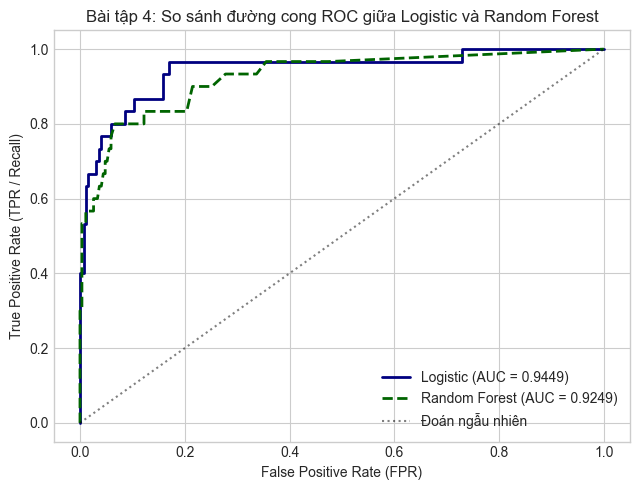

In [11]:
rf_model = RandomForestClassifier(200, random_state=0).fit(X_tr, y_tr)
p_rf = rf_model.predict_proba(X_te)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(y_te, xs_te)
fpr_rf, tpr_rf, _ = roc_curve(y_te, p_rf)

auc_lr = roc_auc_score(y_te, xs_te)
auc_rf = roc_auc_score(y_te, p_rf)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(fpr_lr, tpr_lr, 'navy', lw=2, label=f"Logistic (AUC = {auc_lr:.4f})")
ax.plot(fpr_rf, tpr_rf, 'darkgreen', lw=2, linestyle='--', label=f"Random Forest (AUC = {auc_rf:.4f})")
ax.plot([0, 1], [0, 1], 'k:', alpha=0.5, label="Đoán ngẫu nhiên")
ax.set_xlabel("False Positive Rate (FPR)")
ax.set_ylabel("True Positive Rate (TPR / Recall)")
ax.set_title("Bài tập 4: So sánh đường cong ROC giữa Logistic và Random Forest")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc.png", dpi=150)
print("Đã lưu hình ảnh đường ROC thành công vào tệp 'roc.png'!")
plt.show()


### Bài tập 5: Cân bằng lớp cho Random Forest và SVM


In [12]:
mo_hinh_cb = {
    "Random Forest (gốc)"      : RandomForestClassifier(200, random_state=0),
    "Random Forest (balanced)" : RandomForestClassifier(200, class_weight="balanced", random_state=0),
    "SVM RBF (gốc)"            : make_pipeline(StandardScaler(), SVC(random_state=0)),
    "SVM RBF (balanced)"       : make_pipeline(StandardScaler(), SVC(class_weight="balanced", random_state=0))
}

print("So sánh hiệu năng trước và sau khi cân bằng lớp:")
print("Mô hình                        Precision   Recall     F1")
for ten, m in mo_hinh_cb.items():
    m.fit(X_tr, y_tr)
    preds = m.predict(X_te)
    print(f" {ten:30s} {precision_score(y_te, preds):.4f}     {recall_score(y_te, preds):.4f}   {f1_score(y_te, preds):.4f}")


So sánh hiệu năng trước và sau khi cân bằng lớp:
Mô hình                        Precision   Recall     F1
 Random Forest (gốc)            0.7727     0.5667   0.6538
 Random Forest (balanced)       0.7500     0.4000   0.5217
 SVM RBF (gốc)                  0.8824     0.5000   0.6383
 SVM RBF (balanced)             0.4464     0.8333   0.5814


### Bài tập 6: MAE, RMSE và $R^2$ khi có một dự đoán hỏng


In [13]:
path_nha = "data/gia_nha.csv" if os.path.exists("data/gia_nha.csv") else "gia_nha.csv"
df_nha = pd.read_csv(path_nha)
X_n = df_nha[["dien_tich"]]
y_n = df_nha["gia"]
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(X_n, y_n, test_size=0.2, random_state=42)

lr_nha = LinearRegression().fit(Xn_tr, yn_tr)
pred_goc = lr_nha.predict(Xn_te)

# Giả lập dự đoán hỏng: cộng thêm 5 tỷ vào 1 căn
pred_hong = pred_goc.copy()
pred_hong[0] += 5.0

print("So sánh các thước đo khi có 1 điểm sai số lớn (+5 tỷ):")
print(f"  Gốc  : MAE = {mean_absolute_error(yn_te, pred_goc):.4f} | RMSE = {np.sqrt(mean_squared_error(yn_te, pred_goc)):.4f} | R2 = {r2_score(yn_te, pred_goc):.4f}")
print(f"  Hỏng : MAE = {mean_absolute_error(yn_te, pred_hong):.4f} | RMSE = {np.sqrt(mean_squared_error(yn_te, pred_hong)):.4f} | R2 = {r2_score(yn_te, pred_hong):.4f}")
print(f"  Tăng : MAE tăng {mean_absolute_error(yn_te, pred_hong)/mean_absolute_error(yn_te, pred_goc):.2f} lần | RMSE tăng {np.sqrt(mean_squared_error(yn_te, pred_hong))/np.sqrt(mean_squared_error(yn_te, pred_goc)):.2f} lần")


So sánh các thước đo khi có 1 điểm sai số lớn (+5 tỷ):
  Gốc  : MAE = 0.2578 | RMSE = 0.3730 | R2 = 0.9622
  Hỏng : MAE = 0.6745 | RMSE = 1.5505 | R2 = 0.3475
  Tăng : MAE tăng 2.62 lần | RMSE tăng 4.16 lần
